## 1. Install Dependencies & Hugging Face Login

In [1]:
!pip install -q bert-score tokenizers ijson

import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Hugging Face login successful.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 4.4 MB/s eta 0:00:00


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

CUDA available: True
GPU count: 2
GPU: Tesla T4
VRAM: 15.6 GB
Using device: cuda


## 3. Configuration

In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil
import numpy as np
from dataclasses import dataclass
from tqdm.auto import tqdm

# === Reproducibility ===
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# === Dataset Input Paths ===
DATASET_INPUT_DIR = "/kaggle/input/datasets/krkanhaiya24/m2-500m-dataset"
PREPROCESSED_DIR = os.path.join(DATASET_INPUT_DIR, "cs781_phase1_encdec")

# === Dataset ===
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
SOURCE_WEIGHTS = {
    "train_supreme_court.json": 0.40,
    "train_high_courts.json": 0.30,
    "train_acts.json": 0.15,
    "train_tribunals.json": 0.15,
}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# === Model Architecture (Encoder-Decoder) ===
VOCAB_SIZE = 32000        # Custom BPE tokenizer
D_MODEL = 768
ENC_LAYERS = 8            # Encoder: 8 layers (bidirectional)
DEC_LAYERS = 4            # Decoder: 4 layers (causal + cross-attention)
N_HEADS = 12
HEAD_DIM = D_MODEL // N_HEADS  # 64
D_FF = 2048               # SwiGLU intermediate size
MAX_ENC_LEN = 1088         # Max encoder input length (prompt)
MAX_DEC_LEN = 384         # Max decoder output length (continuation)
ROPE_BASE = 10000.0
DROPOUT = 0.1             # Mild dropout for enc-dec

# === Training ===
TOTAL_TOKENS = 500_000_000       # 500M tokens total
BATCH_SIZE = 8                    # micro batch size (pairs per step)
GRADIENT_ACCUMULATION_STEPS = 8   # effective batch = 8 * 8 = 64 pairs
PEAK_LR = 5e-4
MIN_LR = 5e-6
WARMUP_STEPS = 2000
WEIGHT_DECAY = 0.1
BETA1 = 0.9
BETA2 = 0.95
GRAD_CLIP = 1.0

# === Training Objective Mixing ===
DENOISE_PROB = 0.7                # Probability of denoising objective per batch
CONTINUATION_PROB = 0.3           # Probability of continuation objective per batch
MASK_TOKEN_STR = "<|mask|>"       # Sentinel token for text infilling
POISSON_LAMBDA = 3                # Mean span length for text infilling

# === Validation ===
VAL_PAIRS = 2000           # Number of validation pairs
VAL_INTERVAL_STEPS = 500

# === Generation (defaults, will be optimized in Cell 25) ===
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384

# === Decoding Strategy Search ===
DECODING_SEARCH_SAMPLES = 50     # Number of validation samples for decoding search

# === Checkpointing ===
SAVE_INTERVAL_STEPS = 2000
SAVE_TOTAL_LIMIT = 3

# === Tokenizer ===
TOKENIZER_VOCAB_SIZE = 32000
TOKENIZER_MIN_FREQ = 2
TOKENIZER_SAMPLE_SIZE = 200_000
TOKENIZER_DIR = os.path.join(DATASET_INPUT_DIR, "legal_tokenizer_encdec")

# === Output Paths ===
OUTPUT_DIR = "/kaggle/working/cs781_phase1_encdec"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-encdec-final")
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

# Use read-only uploaded dataset paths for the precomputed binaries
TRAIN_PAIRS_BIN = os.path.join(PREPROCESSED_DIR, "train_pairs.bin")
TRAIN_PAIRS_IDX = os.path.join(PREPROCESSED_DIR, "train_pairs_index.bin")
VAL_PAIRS_BIN = os.path.join(PREPROCESSED_DIR, "val_pairs.bin")
VAL_PAIRS_IDX = os.path.join(PREPROCESSED_DIR, "val_pairs_index.bin")

# Removed TOKENIZER_DIR from makedirs because it is a read-only Kaggle input path
for d in [OUTPUT_DIR, MODEL_OUTPUT_DIR, CHECKPOINT_DIR]:
    os.makedirs(d, exist_ok=True)

print("Configuration loaded.")
print(f"Architecture: Encoder-Decoder ({ENC_LAYERS}L enc + {DEC_LAYERS}L dec)")
print(f"Effective batch size: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS} pairs")

Configuration loaded.
Architecture: Encoder-Decoder (8L enc + 4L dec)
Effective batch size: 64 pairs


In [4]:
# import os
# import random
# import json
# import time
# import math
# import zipfile
# import shutil
# import numpy as np
# from dataclasses import dataclass
# from tqdm.auto import tqdm

# # === Reproducibility ===
# SEED = 42
# random.seed(SEED)
# np.random.seed(SEED)
# torch.manual_seed(SEED)
# if torch.cuda.is_available():
#     torch.cuda.manual_seed_all(SEED)

# # === Dataset ===
# HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
# TRAIN_FILES = [
#     "Phase_1_Pretraining/Train/train_supreme_court.json",
#     "Phase_1_Pretraining/Train/train_high_courts.json",
#     "Phase_1_Pretraining/Train/train_acts.json",
#     "Phase_1_Pretraining/Train/train_tribunals.json",
# ]
# SOURCE_WEIGHTS = {
#     "train_supreme_court.json": 0.40,
#     "train_high_courts.json": 0.30,
#     "train_acts.json": 0.15,
#     "train_tribunals.json": 0.15,
# }
# TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# # === Model Architecture (Encoder-Decoder) ===
# VOCAB_SIZE = 32000        # Custom BPE tokenizer
# D_MODEL = 768
# ENC_LAYERS = 8            # Encoder: 8 layers (bidirectional)
# DEC_LAYERS = 4            # Decoder: 4 layers (causal + cross-attention)
# N_HEADS = 12
# HEAD_DIM = D_MODEL // N_HEADS  # 64
# D_FF = 2048               # SwiGLU intermediate size
# MAX_ENC_LEN = 768         # Max encoder input length (prompt)
# MAX_DEC_LEN = 256         # Max decoder output length (continuation)
# ROPE_BASE = 10000.0
# DROPOUT = 0.1             # Mild dropout for enc-dec

# # === Training ===
# TOTAL_TOKENS = 500_000_000       # 500M tokens total
# BATCH_SIZE = 8                    # micro batch size (pairs per step)
# GRADIENT_ACCUMULATION_STEPS = 8   # effective batch = 8 * 8 = 64 pairs
# PEAK_LR = 5e-4
# MIN_LR = 5e-6
# WARMUP_STEPS = 2000
# WEIGHT_DECAY = 0.1
# BETA1 = 0.9
# BETA2 = 0.95
# GRAD_CLIP = 1.0

# # === Training Objective Mixing ===
# DENOISE_PROB = 0.7                # Probability of denoising objective per batch
# CONTINUATION_PROB = 0.3           # Probability of continuation objective per batch
# MASK_TOKEN_STR = "<|mask|>"       # Sentinel token for text infilling
# POISSON_LAMBDA = 3                # Mean span length for text infilling

# # === Validation ===
# VAL_PAIRS = 2000           # Number of validation pairs
# VAL_INTERVAL_STEPS = 500

# # === Generation (defaults, will be optimized in Cell 25) ===
# TARGET_GENERATION_WORDS = 128
# MAX_GENERATION_TOKENS = 384

# # === Decoding Strategy Search ===
# DECODING_SEARCH_SAMPLES = 50     # Number of validation samples for decoding search

# # === Checkpointing ===
# SAVE_INTERVAL_STEPS = 2000
# SAVE_TOTAL_LIMIT = 3

# # === Tokenizer ===
# TOKENIZER_VOCAB_SIZE = 32000
# TOKENIZER_MIN_FREQ = 2
# TOKENIZER_SAMPLE_SIZE = 200_000
# TOKENIZER_DIR = "/kaggle/working/legal_tokenizer_encdec"

# # === Output Paths ===
# OUTPUT_DIR = "/kaggle/working/cs781_phase1_encdec"
# MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-encdec-final")
# CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
# PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
# SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
# LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
# TRAIN_PAIRS_BIN = os.path.join(OUTPUT_DIR, "train_pairs.bin")
# TRAIN_PAIRS_IDX = os.path.join(OUTPUT_DIR, "train_pairs_index.bin")
# VAL_PAIRS_BIN = os.path.join(OUTPUT_DIR, "val_pairs.bin")
# VAL_PAIRS_IDX = os.path.join(OUTPUT_DIR, "val_pairs_index.bin")

# for d in [OUTPUT_DIR, MODEL_OUTPUT_DIR, CHECKPOINT_DIR, TOKENIZER_DIR]:
#     os.makedirs(d, exist_ok=True)

# print("Configuration loaded.")
# print(f"Architecture: Encoder-Decoder ({ENC_LAYERS}L enc + {DEC_LAYERS}L dec)")
# print(f"Effective batch size: {BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS} pairs")

In [5]:
from transformers import PreTrainedTokenizerFast

print(f"Loading tokenizer from {TOKENIZER_DIR}...")
# Load the pre-trained tokenizer directly from your mounted dataset
tokenizer = PreTrainedTokenizerFast.from_pretrained(TOKENIZER_DIR)

# Restore the necessary global token IDs that were previously generated during preprocessing
VOCAB_SIZE = len(tokenizer)
MASK_TOKEN_ID = tokenizer.convert_tokens_to_ids(MASK_TOKEN_STR)
PAD_TOKEN_ID = tokenizer.pad_token_id
EOS_TOKEN_ID = tokenizer.eos_token_id
BOS_TOKEN_ID = tokenizer.bos_token_id

print(f"VOCAB_SIZE = {VOCAB_SIZE}")
print(f"MASK_TOKEN_ID = {MASK_TOKEN_ID}")
print(f"PAD_TOKEN_ID = {PAD_TOKEN_ID}")
print(f"EOS_TOKEN_ID = {EOS_TOKEN_ID}")
print(f"BOS_TOKEN_ID = {BOS_TOKEN_ID}")
print("Tokenizer and constants successfully loaded. You can now proceed directly to Cell 7.")

Loading tokenizer from /kaggle/input/datasets/krkanhaiya24/m2-500m-dataset/legal_tokenizer_encdec...
VOCAB_SIZE = 32000
MASK_TOKEN_ID = 4
PAD_TOKEN_ID = 0
EOS_TOKEN_ID = 1
BOS_TOKEN_ID = 2
Tokenizer and constants successfully loaded. You can now proceed directly to Cell 7.


## 4. Download Training & Test Data

In [6]:
# from huggingface_hub import hf_hub_download

# train_file_paths = {}
# for tf in TRAIN_FILES:
#     path = hf_hub_download(
#         repo_id=HF_DATASET_REPO,
#         filename=tf,
#         repo_type="dataset",
#         token=HF_TOKEN,
#     )
#     source_name = os.path.basename(tf)
#     train_file_paths[source_name] = path
#     print(f"Downloaded {source_name}: {path}")

# test_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO,
#     filename=TEST_FILE,
#     repo_type="dataset",
#     token=HF_TOKEN,
# )
# print(f"\nTest file: {test_file_path}")

## 5. Train BPE Tokenizer on Legal Corpus

In [7]:
# from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
# from transformers import PreTrainedTokenizerFast
# import ijson
# import gc

# # --- Step 1: Collect training texts via streaming (identical to Model 1) ---
# print("Collecting texts for tokenizer training via weighted streaming...")

# tokenizer_quotas = {k: int(TOKENIZER_SAMPLE_SIZE * v) for k, v in SOURCE_WEIGHTS.items()}
# tokenizer_texts = []
# random.seed(SEED)

# for source_name, fpath in train_file_paths.items():
#     target_sample_size = tokenizer_quotas.get(source_name, 0)
#     print(f"\nTarget sample for {source_name}: {target_sample_size} docs")
    
#     file_sampled_texts = []
#     docs_seen = 0
    
#     with open(fpath, "rb") as f:
#         records = ijson.items(f, "item")
#         for rec in tqdm(records, desc=f"Streaming {source_name}", unit=" docs"):
#             docs_seen += 1
#             text = rec.get("text", "")
#             if not text.strip():
#                 continue
#             # Reservoir sampling
#             if len(file_sampled_texts) < target_sample_size:
#                 file_sampled_texts.append(text)
#             else:
#                 j = random.randint(0, docs_seen - 1)
#                 if j < target_sample_size:
#                     file_sampled_texts[j] = text
    
#     tokenizer_texts.extend(file_sampled_texts)
#     print(f"  Sampled {len(file_sampled_texts)} docs from {docs_seen} total")

# print(f"\nTotal tokenizer training docs: {len(tokenizer_texts)}")

# # --- Step 2: Write to temp file ---
# tokenizer_train_file = os.path.join(TOKENIZER_DIR, "tokenizer_train_corpus.txt")
# with open(tokenizer_train_file, "w", encoding="utf-8") as f:
#     for text in tqdm(tokenizer_texts, desc="Writing corpus"):
#         clean_text = text.replace("\n", " ").replace("\r", " ").strip()
#         if clean_text:
#             f.write(clean_text + "\n")

# del tokenizer_texts
# gc.collect()

# # --- Step 3: Train BPE tokenizer ---
# print(f"\nTraining BPE tokenizer (vocab_size={TOKENIZER_VOCAB_SIZE})...")

# # Special tokens — NOTE: <|mask|> added for denoising objective
# SPECIAL_TOKENS = ["<|pad|>", "<|eos|>", "<|bos|>", "<|unk|>", "<|mask|>"]

# tok = Tokenizer(models.BPE(unk_token="<|unk|>"))
# tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
# tok.decoder = decoders.ByteLevel()
# tok.post_processor = processors.ByteLevel(trim_offsets=True)

# trainer = trainers.BpeTrainer(
#     vocab_size=TOKENIZER_VOCAB_SIZE,
#     min_frequency=TOKENIZER_MIN_FREQ,
#     special_tokens=SPECIAL_TOKENS,
#     show_progress=True,
#     initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
# )

# tok.train(files=[tokenizer_train_file], trainer=trainer)
# print(f"Tokenizer trained! Vocab size: {tok.get_vocab_size()}")

# # --- Step 4: Save and wrap ---
# raw_tokenizer_path = os.path.join(TOKENIZER_DIR, "tokenizer.json")
# tok.save(raw_tokenizer_path)

# tokenizer = PreTrainedTokenizerFast(
#     tokenizer_object=tok,
#     unk_token="<|unk|>",
#     eos_token="<|eos|>",
#     bos_token="<|bos|>",
#     pad_token="<|pad|>",
#     mask_token="<|mask|>",
# )
# tokenizer.save_pretrained(TOKENIZER_DIR)

# # --- Step 5: Update VOCAB_SIZE ---
# VOCAB_SIZE = len(tokenizer)
# MASK_TOKEN_ID = tokenizer.convert_tokens_to_ids(MASK_TOKEN_STR)
# PAD_TOKEN_ID = tokenizer.pad_token_id
# EOS_TOKEN_ID = tokenizer.eos_token_id
# BOS_TOKEN_ID = tokenizer.bos_token_id

# print(f"\nVOCAB_SIZE = {VOCAB_SIZE}")
# print(f"MASK_TOKEN_ID = {MASK_TOKEN_ID}")
# print(f"PAD_TOKEN_ID = {PAD_TOKEN_ID}")
# print(f"EOS_TOKEN_ID = {EOS_TOKEN_ID}")
# print(f"BOS_TOKEN_ID = {BOS_TOKEN_ID}")

# # Quick quality check
# test_sentences = [
#     "The appellant herein is the original plaintiff in the suit.",
#     "Section 302 of the Indian Penal Code, 1860, deals with punishment for murder.",
#     "Notwithstanding anything contained in sub-section (1), the Central Government may",
# ]
# print("\n--- Tokenizer Quality Check ---")
# for sent in test_sentences:
#     tokens = tokenizer.encode(sent, add_special_tokens=False)
#     decoded = tokenizer.decode(tokens)
#     ratio = len(sent.split()) / len(tokens)
#     print(f"  [{len(tokens):3d} tok, {ratio:.2f} w/t] {sent[:80]}...")
#     assert decoded.strip() == sent.strip(), f"Round-trip failed!"
# print("All round-trip checks passed!")

# # Clean up
# if os.path.exists(tokenizer_train_file):
#     os.remove(tokenizer_train_file)

## 6. Create Encoder-Decoder Training Pairs on Disk

In [8]:
# import ijson
# import struct
# import gc

# # === Text Infilling (BART-style corruption) ===
# def corrupt_text_infilling(token_ids, mask_token_id, poisson_lambda=3, rng=None):
#     """
#     Apply BART-style text infilling corruption.
#     - Sample random spans with lengths from Poisson(lambda)
#     - Replace each span with a single <mask> token
#     Returns the corrupted token list.
#     """
#     if rng is None:
#         rng = random.Random()
    
#     tokens = list(token_ids)
#     n = len(tokens)
#     if n < 10:  # Too short to corrupt meaningfully
#         return tokens
    
#     # Target: mask about 30% of tokens
#     target_masked = int(n * 0.3)
#     masked_so_far = 0
#     result = []
#     i = 0
    
#     while i < n and masked_so_far < target_masked:
#         # Randomly decide whether to start a span here
#         remaining = n - i
#         remaining_to_mask = target_masked - masked_so_far
#         # Probability of starting a mask span at this position
#         if remaining > 0 and rng.random() < (remaining_to_mask / remaining) * 0.5:
#             # Sample span length from Poisson
#             span_len = max(1, min(rng.poisson(poisson_lambda) if hasattr(rng, 'poisson') else 
#                           int(np.random.poisson(poisson_lambda)), remaining - 1))
#             result.append(mask_token_id)  # Single mask token replaces entire span
#             i += span_len
#             masked_so_far += span_len
#         else:
#             result.append(tokens[i])
#             i += 1
    
#     # Append remaining tokens
#     result.extend(tokens[i:])
#     return result


# def create_pair_from_document(token_ids, objective, mask_token_id, eos_token_id, 
#                                 max_enc_len, max_dec_len, rng):
#     """
#     Create an (encoder_input, decoder_target) pair from a tokenized document.
    
#     objective: 'denoise' or 'continuation'
#     """
#     n = len(token_ids)
    
#     if objective == 'denoise':
#         # Split document: first 70% for context, last 30% for target
#         split_point = int(n * 0.7)
#         context_tokens = token_ids[:split_point]
#         target_tokens = token_ids[split_point:]
        
#         # Corrupt the context via text infilling
#         corrupted_context = corrupt_text_infilling(context_tokens, mask_token_id, 
#                                                     POISSON_LAMBDA, rng)
        
#         enc_input = corrupted_context[:max_enc_len]
#         dec_target = target_tokens[:max_dec_len - 1] + [eos_token_id]
        
#     else:  # continuation
#         # Split document: first 80% as encoder input, last 20% as target
#         split_point = int(n * 0.8)
#         enc_input = token_ids[:split_point][-max_enc_len:]  # Take last max_enc_len tokens
#         dec_target = token_ids[split_point:][:max_dec_len - 1] + [eos_token_id]
    
#     return enc_input, dec_target


# # === Stream through all files and create pairs ===
# print("Creating encoder-decoder training pairs on disk...")

# rng = random.Random(SEED)
# np_rng = np.random.RandomState(SEED)

# # Open binary files for writing
# train_f = open(TRAIN_PAIRS_BIN, "wb")
# train_idx_f = open(TRAIN_PAIRS_IDX, "wb")
# val_f = open(VAL_PAIRS_BIN, "wb")
# val_idx_f = open(VAL_PAIRS_IDX, "wb")

# train_pair_count = 0
# val_pair_count = 0
# train_byte_offset = 0
# val_byte_offset = 0
# total_docs = 0
# total_train_tokens = 0

# for source_name, fpath in train_file_paths.items():
#     print(f"\nProcessing {source_name}...")
    
#     with open(fpath, "rb") as f:
#         records = ijson.items(f, "item")
        
#         for rec in tqdm(records, desc=f"  {source_name}", unit=" docs"):
#             text = rec.get("text", "")
#             if not text.strip() or len(text.split()) < 50:  # Skip very short docs
#                 continue
            
#             total_docs += 1
            
#             # Tokenize
#             token_ids = tokenizer.encode(text, add_special_tokens=False)
            
#             if len(token_ids) < 100:  # Need enough tokens for meaningful pairs
#                 continue
            
#             # Decide: validation or training (3% validation)
#             is_val = rng.random() < 0.03 and val_pair_count < VAL_PAIRS
            
#             if is_val:
#                 # Validation: always use continuation objective (matches eval task)
#                 enc_input, dec_target = create_pair_from_document(
#                     token_ids, 'continuation', MASK_TOKEN_ID, EOS_TOKEN_ID,
#                     MAX_ENC_LEN, MAX_DEC_LEN, rng
#                 )
                
#                 # Write to val binary: [enc_len, enc_tokens..., dec_len, dec_tokens...]
#                 enc_arr = np.array(enc_input, dtype=np.uint32)
#                 dec_arr = np.array(dec_target, dtype=np.uint32)
                
#                 val_idx_f.write(struct.pack("Q", val_byte_offset))  # 8-byte offset
                
#                 header = np.array([len(enc_input), len(dec_target)], dtype=np.uint32)
#                 val_f.write(header.tobytes())
#                 val_f.write(enc_arr.tobytes())
#                 val_f.write(dec_arr.tobytes())
                
#                 val_byte_offset += header.nbytes + enc_arr.nbytes + dec_arr.nbytes
#                 val_pair_count += 1
                
#             else:
#                 # Training: randomly choose objective
#                 objective = 'denoise' if rng.random() < DENOISE_PROB else 'continuation'
                
#                 enc_input, dec_target = create_pair_from_document(
#                     token_ids, objective, MASK_TOKEN_ID, EOS_TOKEN_ID,
#                     MAX_ENC_LEN, MAX_DEC_LEN, rng
#                 )
                
#                 enc_arr = np.array(enc_input, dtype=np.uint32)
#                 dec_arr = np.array(dec_target, dtype=np.uint32)
                
#                 train_idx_f.write(struct.pack("Q", train_byte_offset))
                
#                 header = np.array([len(enc_input), len(dec_target)], dtype=np.uint32)
#                 train_f.write(header.tobytes())
#                 train_f.write(enc_arr.tobytes())
#                 train_f.write(dec_arr.tobytes())
                
#                 train_byte_offset += header.nbytes + enc_arr.nbytes + dec_arr.nbytes
#                 total_train_tokens += len(enc_input) + len(dec_target)
#                 train_pair_count += 1

# # Close files
# for f in [train_f, train_idx_f, val_f, val_idx_f]:
#     f.close()

# print(f"\nTotal documents processed: {total_docs}")
# print(f"Training pairs: {train_pair_count:,}")
# print(f"Validation pairs: {val_pair_count:,}")
# print(f"Approx. training tokens: {total_train_tokens:,}")
# print(f"Train binary size: {os.path.getsize(TRAIN_PAIRS_BIN) / 1e6:.1f} MB")
# print(f"Val binary size: {os.path.getsize(VAL_PAIRS_BIN) / 1e6:.1f} MB")

# gc.collect()

## 7. Memory-Mapped Encoder-Decoder DataLoader

In [9]:
import struct
from torch.utils.data import IterableDataset, DataLoader

class EncDecPairDataset(IterableDataset):
    """
    Memory-mapped dataset for encoder-decoder training pairs.
    Reads pairs from binary files with zero RAM overhead.
    """
    def __init__(self, pairs_bin_path, pairs_idx_path, batch_size, 
                 pad_token_id, eos_token_id, bos_token_id, seed=42):
        self.pairs_bin_path = pairs_bin_path
        self.pad_token_id = pad_token_id
        self.eos_token_id = eos_token_id
        self.bos_token_id = bos_token_id
        self.batch_size = batch_size
        self.rng = random.Random(seed)
        
        # Load index (small: 8 bytes per pair)
        idx_size = os.path.getsize(pairs_idx_path)
        self.num_pairs = idx_size // 8  # Each offset is 8 bytes (uint64)
        with open(pairs_idx_path, "rb") as f:
            self.offsets = struct.unpack(f"{self.num_pairs}Q", f.read())
        
        print(f"  Loaded index: {self.num_pairs:,} pairs")
        
        # Memory-map the data file
        self.data_mmap = open(pairs_bin_path, "rb")
    
    def _read_pair(self, idx):
        offset = self.offsets[idx]
        self.data_mmap.seek(offset)
    
        header = np.frombuffer(self.data_mmap.read(8), dtype=np.uint32)
        enc_len, dec_len = int(header[0]), int(header[1])
    
        enc_tokens = np.frombuffer(self.data_mmap.read(enc_len * 4), dtype=np.uint32).astype(np.int64)
        dec_tokens = np.frombuffer(self.data_mmap.read(dec_len * 4), dtype=np.uint32).astype(np.int64)
    
        # Encoder: keep the tokens closest to the continuation point
        if len(enc_tokens) > MAX_ENC_LEN:
            enc_tokens = enc_tokens[-MAX_ENC_LEN:]
    
        # Decoder: keep the first MAX_DEC_LEN tokens.
        # Do NOT append EOS when cutting. The text didn't actually end there.
        if len(dec_tokens) > MAX_DEC_LEN:
            dec_tokens = dec_tokens[:MAX_DEC_LEN]
    
        return enc_tokens, dec_tokens
    
    def __iter__(self):
        """Yield batches of collated pairs."""
        indices = list(range(self.num_pairs))
        self.rng.shuffle(indices)
        
        batch_enc = []
        batch_dec = []
        
        for idx in indices:
            enc_tokens, dec_tokens = self._read_pair(idx)
            batch_enc.append(enc_tokens)
            batch_dec.append(dec_tokens)
            
            if len(batch_enc) == self.batch_size:
                yield self._collate(batch_enc, batch_dec)
                batch_enc = []
                batch_dec = []
        
        # Yield remaining
        if batch_enc:
            yield self._collate(batch_enc, batch_dec)
    
    def _collate(self, batch_enc, batch_dec):
        """Pad and collate a batch of pairs."""
        max_enc = max(len(e) for e in batch_enc)
        max_dec = max(len(d) for d in batch_dec)
        
        B = len(batch_enc)
        
        # Encoder input + attention mask
        enc_input = np.full((B, max_enc), self.pad_token_id, dtype=np.int64)
        enc_mask = np.zeros((B, max_enc), dtype=np.int64)
        
        # Decoder input (shifted right: BOS + target[:-1]) and target (for loss)
        dec_input = np.full((B, max_dec), self.pad_token_id, dtype=np.int64)
        dec_target = np.full((B, max_dec), -100, dtype=np.int64)  # -100 = ignore in loss
        
        for i in range(B):
            e_len = len(batch_enc[i])
            enc_input[i, :e_len] = batch_enc[i]
            enc_mask[i, :e_len] = 1
            
            d_len = len(batch_dec[i])
            # Decoder input: BOS + target[:-1]
            dec_input[i, 0] = self.bos_token_id
            dec_input[i, 1:d_len] = batch_dec[i][:d_len - 1]
            # Decoder target: target tokens (no BOS)
            dec_target[i, :d_len] = batch_dec[i]
        
        return {
            "enc_input": torch.tensor(enc_input, dtype=torch.long),
            "enc_mask": torch.tensor(enc_mask, dtype=torch.long),
            "dec_input": torch.tensor(dec_input, dtype=torch.long),
            "dec_target": torch.tensor(dec_target, dtype=torch.long),
        }


# === Create datasets ===
train_dataset = EncDecPairDataset(
    TRAIN_PAIRS_BIN, TRAIN_PAIRS_IDX, BATCH_SIZE,
    PAD_TOKEN_ID, EOS_TOKEN_ID, BOS_TOKEN_ID, seed=SEED,
)

# Create train DataLoader with prefetching
train_loader = DataLoader(
    train_dataset,
    batch_size=None,  # Dataset already returns batches
    num_workers=2,
    prefetch_factor=2,
    pin_memory=True,
)

# Calculate total steps
tokens_per_pair = (MAX_ENC_LEN + MAX_DEC_LEN) // 2  # Average
pairs_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
steps_from_pairs = train_dataset.num_pairs // pairs_per_step
TOTAL_STEPS = min(steps_from_pairs, TOTAL_TOKENS // (pairs_per_step * tokens_per_pair))

print(f"\nTotal training pairs: {train_dataset.num_pairs:,}")
print(f"Pairs per optimizer step: {pairs_per_step}")
print(f"Total optimizer steps: {TOTAL_STEPS:,}")

  Loaded index: 3,354,277 pairs

Total training pairs: 3,354,277
Pairs per optimizer step: 64
Total optimizer steps: 10,614


## 8. Learning Rate Scheduler

In [10]:
class WSDScheduler:
    """Warmup-Stable-Decay learning rate scheduler."""
    def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_fraction=0.10):
        self.peak_lr = peak_lr
        self.min_lr = min_lr
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.decay_start = int(total_steps * (1.0 - decay_fraction))
        self.decay_steps = total_steps - self.decay_start
    
    def get_lr(self, step):
        if step < self.warmup_steps:
            return self.peak_lr * (step / max(self.warmup_steps, 1))
        elif step < self.decay_start:
            return self.peak_lr
        else:
            progress = (step - self.decay_start) / max(self.decay_steps, 1)
            cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
            return self.min_lr + (self.peak_lr - self.min_lr) * cosine_decay

lr_scheduler = WSDScheduler(PEAK_LR, MIN_LR, WARMUP_STEPS, TOTAL_STEPS)
print(f"LR Schedule: warmup {WARMUP_STEPS} steps -> stable -> decay last 10%")

LR Schedule: warmup 2000 steps -> stable -> decay last 10%


## 9. Model: RMSNorm

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    
    def forward(self, x):
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).type_as(x) * self.weight

## 10. Model: RoPE

In [12]:
def precompute_rope_freqs(dim, max_seq_len, base=10000.0):
    freqs = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
    t = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(t, freqs)
    return torch.cos(freqs), torch.sin(freqs)

def apply_rope(x, freqs_cos, freqs_sin):
    """Apply RoPE to x. x: (B, n_heads, T, head_dim)"""
    x_r = x.reshape(*x.shape[:-1], -1, 2)
    x0, x1 = x_r[..., 0], x_r[..., 1]
    seq_len = x.shape[2]
    cos = freqs_cos[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    sin = freqs_sin[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    out0 = x0 * cos - x1 * sin
    out1 = x0 * sin + x1 * cos
    return torch.stack([out0, out1], dim=-1).reshape_as(x)

## 11. Model: Encoder Self-Attention (Bidirectional)

In [13]:
class EncoderSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, dropout=0.0):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = head_dim
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        self.resid_dropout = nn.Dropout(dropout)
    
    def forward(self, x, freqs_cos, freqs_sin, key_padding_mask=None):
        """
        x: (B, T, d_model)
        key_padding_mask: (B, T) — True where padding, False where real tokens
        """
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        
        q = apply_rope(q, freqs_cos, freqs_sin)
        k = apply_rope(k, freqs_cos, freqs_sin)
        
        # Build attention mask from key_padding_mask
        attn_mask = None
        if key_padding_mask is not None:
            # key_padding_mask: (B, T) -> expand to (B, 1, 1, T) for broadcasting
            attn_mask = key_padding_mask.unsqueeze(1).unsqueeze(2)  # (B, 1, 1, T)
            attn_mask = attn_mask.float() * torch.finfo(x.dtype).min
        
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, 
                                              dropout_p=self.resid_dropout.p if self.training else 0.0)
        out = out.transpose(1, 2).contiguous().view(B, T, -1)
        return self.resid_dropout(self.out_proj(out))

## 12. Model: Decoder Self-Attention (Causal + KV Cache)

In [14]:
class DecoderSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, dropout=0.0):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = head_dim
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        self.resid_dropout = nn.Dropout(dropout)
    
    def forward(self, x, freqs_cos, freqs_sin, use_cache=False, past_key_value=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        
        q = apply_rope(q, freqs_cos, freqs_sin)
        k = apply_rope(k, freqs_cos, freqs_sin)
        
        if past_key_value is not None:
            k = torch.cat([past_key_value[0], k], dim=2)
            v = torch.cat([past_key_value[1], v], dim=2)
        
        new_kv = (k, v) if use_cache else None
        
        out = F.scaled_dot_product_attention(q, k, v, is_causal=(past_key_value is None),
                                              dropout_p=self.resid_dropout.p if self.training else 0.0)
        out = out.transpose(1, 2).contiguous().view(B, T, -1)
        return self.resid_dropout(self.out_proj(out)), new_kv

## 13. Model: Cross-Attention (Decoder → Encoder)

In [15]:
class CrossAttention(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, dropout=0.0):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = head_dim
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        self.resid_dropout = nn.Dropout(dropout)
    
    def forward(self, x, encoder_output, encoder_mask=None, 
                use_cache=False, past_cross_kv=None):
        """
        x: (B, T_dec, d_model) — decoder hidden states
        encoder_output: (B, T_enc, d_model) — encoder output
        encoder_mask: (B, T_enc) — 0 for padding, 1 for real tokens
        past_cross_kv: cached (k, v) from encoder (static during generation)
        """
        B, T_dec, _ = x.shape
        
        q = self.q_proj(x).view(B, T_dec, self.n_heads, self.head_dim).transpose(1, 2)
        
        if past_cross_kv is not None:
            k, v = past_cross_kv
        else:
            T_enc = encoder_output.shape[1]
            k = self.k_proj(encoder_output).view(B, T_enc, self.n_heads, self.head_dim).transpose(1, 2)
            v = self.v_proj(encoder_output).view(B, T_enc, self.n_heads, self.head_dim).transpose(1, 2)
        
        new_cross_kv = (k, v) if use_cache else None
        
        # Build attention mask from encoder padding mask
        attn_mask = None
        if encoder_mask is not None:
            # encoder_mask: (B, T_enc) -> (B, 1, 1, T_enc)
            pad_mask = (1 - encoder_mask).bool().unsqueeze(1).unsqueeze(2)
            attn_mask = pad_mask.float() * torch.finfo(x.dtype).min
        
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                              dropout_p=self.resid_dropout.p if self.training else 0.0)
        out = out.transpose(1, 2).contiguous().view(B, T_dec, -1)
        return self.resid_dropout(self.out_proj(out)), new_cross_kv

## 14. Model: SwiGLU FFN

In [16]:
class SwiGLU_FFN(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__()
        self.w_gate = nn.Linear(d_model, d_ff, bias=False)
        self.w_up = nn.Linear(d_model, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        return self.dropout(self.w_down(F.silu(self.w_gate(x)) * self.w_up(x)))

## 15. Model: Encoder Block

In [17]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, d_ff, dropout=0.0):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attn = EncoderSelfAttention(d_model, n_heads, head_dim, dropout)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU_FFN(d_model, d_ff, dropout)
    
    def forward(self, x, freqs_cos, freqs_sin, key_padding_mask=None):
        x = x + self.attn(self.attn_norm(x), freqs_cos, freqs_sin, key_padding_mask)
        x = x + self.ffn(self.ffn_norm(x))
        return x

## 16. Model: Decoder Block

In [18]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, d_ff, dropout=0.0):
        super().__init__()
        self.self_attn_norm = RMSNorm(d_model)
        self.self_attn = DecoderSelfAttention(d_model, n_heads, head_dim, dropout)
        self.cross_attn_norm = RMSNorm(d_model)
        self.cross_attn = CrossAttention(d_model, n_heads, head_dim, dropout)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU_FFN(d_model, d_ff, dropout)
    
    def forward(self, x, encoder_output, freqs_cos, freqs_sin, 
                encoder_mask=None, use_cache=False, 
                past_self_kv=None, past_cross_kv=None):
        # Self-attention (causal)
        attn_out, new_self_kv = self.self_attn(
            self.self_attn_norm(x), freqs_cos, freqs_sin, use_cache, past_self_kv
        )
        x = x + attn_out
        
        # Cross-attention (decoder -> encoder)
        cross_out, new_cross_kv = self.cross_attn(
            self.cross_attn_norm(x), encoder_output, encoder_mask, 
            use_cache, past_cross_kv
        )
        x = x + cross_out
        
        # FFN
        x = x + self.ffn(self.ffn_norm(x))
        
        return x, new_self_kv, new_cross_kv

## 17. Full Model: LegalEncDec

In [19]:
from torch.utils.checkpoint import checkpoint as grad_checkpoint

class LegalEncDec(nn.Module):
    def __init__(self, vocab_size, d_model, enc_layers, dec_layers, n_heads, head_dim, d_ff,
                 max_enc_len, max_dec_len, rope_base=10000.0, dropout=0.0,
                 use_gradient_checkpointing=True):
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.enc_layers_n = enc_layers
        self.dec_layers_n = dec_layers
        self.max_enc_len = max_enc_len
        self.max_dec_len = max_dec_len
        self.use_gradient_checkpointing = use_gradient_checkpointing
        
        # Shared embedding (3-way tied: enc input, dec input, lm head)
        self.shared_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        
        # Encoder
        self.encoder_layers = nn.ModuleList([
            EncoderBlock(d_model, n_heads, head_dim, d_ff, dropout)
            for _ in range(enc_layers)
        ])
        self.encoder_norm = RMSNorm(d_model)
        
        # Decoder
        self.decoder_layers = nn.ModuleList([
            DecoderBlock(d_model, n_heads, head_dim, d_ff, dropout)
            for _ in range(dec_layers)
        ])
        self.decoder_norm = RMSNorm(d_model)
        
        # LM head (tied)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.shared_emb.weight
        
        # RoPE freqs (separate for enc and dec since they may have different max lengths)
        enc_cos, enc_sin = precompute_rope_freqs(head_dim, max_enc_len, rope_base)
        dec_cos, dec_sin = precompute_rope_freqs(head_dim, max_dec_len, rope_base)
        self.register_buffer("enc_freqs_cos", enc_cos, persistent=False)
        self.register_buffer("enc_freqs_sin", enc_sin, persistent=False)
        self.register_buffer("dec_freqs_cos", dec_cos, persistent=False)
        self.register_buffer("dec_freqs_sin", dec_sin, persistent=False)
        
        self._init_weights()
    
    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
                if module.bias is not None:
                    torch.nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Embedding):
                torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        
        # Scale residual projections
        total_layers = self.enc_layers_n + self.dec_layers_n
        for layer in self.encoder_layers:
            torch.nn.init.normal_(layer.attn.out_proj.weight, std=0.02/math.sqrt(2*total_layers))
            torch.nn.init.normal_(layer.ffn.w_down.weight, std=0.02/math.sqrt(2*total_layers))
        for layer in self.decoder_layers:
            torch.nn.init.normal_(layer.self_attn.out_proj.weight, std=0.02/math.sqrt(2*total_layers))
            torch.nn.init.normal_(layer.cross_attn.out_proj.weight, std=0.02/math.sqrt(2*total_layers))
            torch.nn.init.normal_(layer.ffn.w_down.weight, std=0.02/math.sqrt(2*total_layers))
    
    def encode(self, enc_input, enc_mask=None):
        """Run encoder. Returns encoder output (B, T_enc, d_model)."""
        x = self.emb_dropout(self.shared_emb(enc_input))
        
        # Create padding mask: True where pad, False where real
        key_padding_mask = None
        if enc_mask is not None:
            key_padding_mask = (1 - enc_mask).bool()
        
        for layer in self.encoder_layers:
            if self.use_gradient_checkpointing and self.training:
                x = grad_checkpoint(
                    layer, x, self.enc_freqs_cos, self.enc_freqs_sin, key_padding_mask,
                    use_reentrant=False,
                )
            else:
                x = layer(x, self.enc_freqs_cos, self.enc_freqs_sin, key_padding_mask)
        
        return self.encoder_norm(x)
    
    def decode(self, dec_input, encoder_output, encoder_mask=None, 
               use_cache=False, past_kvs=None):
        """
        Run decoder. Returns logits and (optionally) updated KV caches.
        past_kvs: list of (past_self_kv, past_cross_kv) per layer
        """
        x = self.emb_dropout(self.shared_emb(dec_input))
        
        new_kvs = []
        for i, layer in enumerate(self.decoder_layers):
            past_self_kv = past_kvs[i][0] if past_kvs is not None else None
            past_cross_kv = past_kvs[i][1] if past_kvs is not None else None
            
            x, new_self_kv, new_cross_kv = layer(
                x, encoder_output, self.dec_freqs_cos, self.dec_freqs_sin,
                encoder_mask, use_cache, past_self_kv, past_cross_kv
            )
            if use_cache:
                new_kvs.append((new_self_kv, new_cross_kv))
        
        x = self.decoder_norm(x)
        logits = self.lm_head(x)
        
        return logits, new_kvs if use_cache else None
    
    def forward(self, enc_input, enc_mask, dec_input, dec_target):
        """Full forward pass for training. Returns loss."""
        encoder_output = self.encode(enc_input, enc_mask)
        logits, _ = self.decode(dec_input, encoder_output, enc_mask)
        
        # Compute loss (ignore -100 padding in targets)
        loss = F.cross_entropy(
            logits.view(-1, self.vocab_size),
            dec_target.view(-1),
            ignore_index=-100,
        )
        return logits, loss
    
    @torch.no_grad()
    def generate(self, enc_input, enc_mask, max_new_tokens, 
                 strategy="nucleus", temperature=0.7, top_p=0.9, top_k=50,
                 num_beams=1, length_penalty=1.0, repetition_penalty=1.1,
                 contrastive_k=4, contrastive_alpha=0.6,
                 eos_token_id=None, bos_token_id=None, pad_token_id=None):
        """
        Autoregressive generation with multiple decoding strategies.
        Supports: greedy, nucleus, beam, contrastive.
        
        Uses KV caching for efficiency:
        - Encoder output computed once
        - Cross-attention K,V computed once per layer (static)
        - Self-attention K,V grow incrementally
        """
        self.eval()
        B = enc_input.shape[0]
        
        # 1. Encode input once
        encoder_output = self.encode(enc_input, enc_mask)
        
        # 2. Start decoder with BOS token
        dec_ids = torch.full((B, 1), bos_token_id, dtype=torch.long, device=enc_input.device)
        past_kvs = None
        
        for step in range(max_new_tokens):
            # Only feed the new token(s) if we have cache
            if past_kvs is not None:
                curr_input = dec_ids[:, -1:]
            else:
                curr_input = dec_ids
            
            logits, past_kvs = self.decode(
                curr_input, encoder_output, enc_mask,
                use_cache=True, past_kvs=past_kvs
            )
            
            next_logits = logits[:, -1, :]  # (B, vocab_size)
            
            # Repetition penalty
            if repetition_penalty != 1.0:
                for b in range(B):
                    for prev_token in set(dec_ids[b].tolist()):
                        if next_logits[b, prev_token] > 0:
                            next_logits[b, prev_token] /= repetition_penalty
                        else:
                            next_logits[b, prev_token] *= repetition_penalty
            
            # Strategy selection
            if strategy == "greedy":
                next_token = next_logits.argmax(dim=-1, keepdim=True)
            
            elif strategy == "nucleus":
                next_logits = next_logits / temperature
                if top_k > 0:
                    topk_vals, _ = torch.topk(next_logits, min(top_k, next_logits.size(-1)))
                    next_logits[next_logits < topk_vals[:, -1:]] = float('-inf')
                if top_p < 1.0:
                    sorted_logits, sorted_idx = torch.sort(next_logits, descending=True)
                    cumprobs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                    remove_mask = cumprobs > top_p
                    remove_mask[:, 1:] = remove_mask[:, :-1].clone()
                    remove_mask[:, 0] = False
                    for b in range(B):
                        next_logits[b, sorted_idx[b][remove_mask[b]]] = float('-inf')
                probs = F.softmax(next_logits, dim=-1)
                next_token = torch.multinomial(probs, num_samples=1)
            
            elif strategy == "contrastive":
                # Contrastive search: balance quality and diversity
                next_logits = next_logits / temperature
                topk_vals, topk_idx = torch.topk(next_logits, contrastive_k, dim=-1)
                # For simplicity in small-batch generation, use nucleus as fallback
                # Full contrastive search requires computing similarity to previous hidden states
                probs = F.softmax(topk_vals, dim=-1)
                chosen = torch.multinomial(probs, num_samples=1)
                next_token = topk_idx.gather(-1, chosen)
            
            else:
                raise ValueError(f"Unknown strategy: {strategy}")
            
            dec_ids = torch.cat([dec_ids, next_token], dim=1)
            
            if eos_token_id is not None and (next_token == eos_token_id).all():
                break
        
        return dec_ids  # (B, seq_len) including BOS


# === Instantiate Model ===
model = LegalEncDec(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    enc_layers=ENC_LAYERS,
    dec_layers=DEC_LAYERS,
    n_heads=N_HEADS,
    head_dim=HEAD_DIM,
    d_ff=D_FF,
    max_enc_len=MAX_ENC_LEN,
    max_dec_len=MAX_DEC_LEN,
    rope_base=ROPE_BASE,
    dropout=DROPOUT,
    use_gradient_checkpointing=True,
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
unique_params = total_params - model.shared_emb.weight.numel()  # lm_head is tied
print(f"Total parameters (unique): {unique_params:,} ({unique_params/1e6:.1f}M)")
assert 50_000_000 <= unique_params <= 300_000_000, f"Model has {unique_params/1e6:.1f}M params!"
print("Model size within allowed range.")

Total parameters (unique): 94,394,880 (94.4M)
Model size within allowed range.


## 18. Optimizer & Mixed Precision

In [20]:
decay_params = []
no_decay_params = []
for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if "norm" in name or "bias" in name or "shared_emb" in name:
        no_decay_params.append(param)
    else:
        decay_params.append(param)

optimizer = torch.optim.AdamW([
    {"params": decay_params, "weight_decay": WEIGHT_DECAY},
    {"params": no_decay_params, "weight_decay": 0.0},
], lr=PEAK_LR, betas=(BETA1, BETA2), fused=True)

scaler = torch.amp.GradScaler("cuda")
print(f"Optimizer: Fused AdamW, {len(decay_params)} decay + {len(no_decay_params)} no-decay params")
print("Mixed precision (FP16) enabled.")

Optimizer: Fused AdamW, 100 decay + 31 no-decay params
Mixed precision (FP16) enabled.


## 19. Validation Function

In [21]:
@torch.no_grad()
def evaluate_val(model, val_dataset, device, max_batches=50):
    """Evaluate on validation pairs. Returns average loss and perplexity."""
    model.eval()
    total_loss = 0.0
    total_batches = 0
    
    val_loader_iter = iter(val_dataset)
    
    for batch in tqdm(val_loader_iter, desc="Validation", leave=False, total=max_batches):
        batch = {k: v.to(device, non_blocking=True) for k, v in batch.items()}
        
        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss = model(
                batch["enc_input"], batch["enc_mask"],
                batch["dec_input"], batch["dec_target"]
            )
        
        total_loss += loss.item()
        total_batches += 1
        if total_batches >= max_batches:
            break
    
    avg_loss = total_loss / max(total_batches, 1)
    ppl = math.exp(min(avg_loss, 20))
    model.train()
    return avg_loss, ppl

# Create val dataset
val_dataset = EncDecPairDataset(
    VAL_PAIRS_BIN, VAL_PAIRS_IDX, BATCH_SIZE * 2,
    PAD_TOKEN_ID, EOS_TOKEN_ID, BOS_TOKEN_ID, seed=SEED,
)

  Loaded index: 2,000 pairs


## 20. Checkpoint Save/Load

In [22]:
def save_checkpoint(model, optimizer, scaler, step, loss, path):
    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "step": step, "loss": loss,
        "config": {
            "vocab_size": VOCAB_SIZE, "d_model": D_MODEL,
            "enc_layers": ENC_LAYERS, "dec_layers": DEC_LAYERS,
            "n_heads": N_HEADS, "head_dim": HEAD_DIM, "d_ff": D_FF,
            "max_enc_len": MAX_ENC_LEN, "max_dec_len": MAX_DEC_LEN,
            "rope_base": ROPE_BASE, "dropout": DROPOUT,
        }
    }, path)
    print(f"  Checkpoint saved: step {step}, loss {loss:.4f}")

def load_checkpoint(path, model, optimizer=None, scaler=None):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    if optimizer and "optimizer_state_dict" in ckpt:
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if scaler and "scaler_state_dict" in ckpt:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    return ckpt["step"], ckpt.get("loss")

def cleanup_checkpoints(ckpt_dir, keep_last_n=3):
    ckpts = sorted([f for f in os.listdir(ckpt_dir) if f.startswith("step_") and f.endswith(".pt")],
                   key=lambda x: int(x.split("_")[1].split(".")[0]))
    while len(ckpts) > keep_last_n:
        os.remove(os.path.join(ckpt_dir, ckpts.pop(0)))

## 21. Training Loop

In [23]:
# TOTAL_STEPS = 5

# # Keep these exactly as your real run
# BATCH_SIZE = 8
# GRADIENT_ACCUMULATION_STEPS = 8
# MAX_ENC_LEN = 768
# MAX_DEC_LEN = 256

# # Exercise validation/checkpoint code
# VAL_INTERVAL_STEPS = 5
# SAVE_INTERVAL_STEPS = 5
# SAVE_TOTAL_LIMIT = 1

In [24]:
model.train()
train_log = []
val_log = []
best_val_loss = float("inf")
start_step = 0

# === RESUME LOGIC ===
# To resume, change None to your specific checkpoint path, e.g.:
# RESUME_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "step_4000.pt")
RESUME_CHECKPOINT_PATH = None 

if RESUME_CHECKPOINT_PATH and os.path.exists(RESUME_CHECKPOINT_PATH):
    print(f"Loading checkpoint: {RESUME_CHECKPOINT_PATH}")
    start_step, _ = load_checkpoint(RESUME_CHECKPOINT_PATH, model, optimizer, scaler)
    # Note: best_val_loss isn't saved in the step_X.pt dict, so it resets to inf, 
    # which is fine as it will quickly self-correct on the next validation step.
    print(f"Successfully restored state from step {start_step}")

print(f"Starting training from step {start_step} to {TOTAL_STEPS} optimizer steps...")
start_time = time.time()
running_loss = 0.0

# Accurately restore tokens_seen so logging metrics don't break
tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * (MAX_ENC_LEN + MAX_DEC_LEN) // 2
tokens_seen = start_step * tokens_per_step

train_iter = iter(train_loader)

# Update the range and initialize tqdm correctly
for step in tqdm(range(start_step, TOTAL_STEPS), desc="Training", initial=start_step, total=TOTAL_STEPS):
    current_lr = lr_scheduler.get_lr(step)
    for pg in optimizer.param_groups:
        pg["lr"] = current_lr

    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0

    for micro_step in range(GRADIENT_ACCUMULATION_STEPS):
        try:
            batch = next(train_iter)
        except StopIteration:
            train_iter = iter(train_loader)
            batch = next(train_iter)

        batch = {k: v.to(device, non_blocking=True) for k, v in batch.items()}

        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss = model(
                batch["enc_input"], batch["enc_mask"],
                batch["dec_input"], batch["dec_target"]
            )
            loss_scaled = loss / GRADIENT_ACCUMULATION_STEPS

        scaler.scale(loss_scaled).backward()
        accum_loss += loss.item()

    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(optimizer)
    scaler.update()

    avg_loss = accum_loss / GRADIENT_ACCUMULATION_STEPS
    running_loss += avg_loss
    tokens_seen += tokens_per_step

    # Logging
    if (step + 1) % 100 == 0:
        elapsed = time.time() - start_time
        avg_running = running_loss / 100
        tps = (tokens_seen - (start_step * tokens_per_step)) / elapsed # tok/s since resume
        train_log.append({"step": step+1, "loss": avg_running, "lr": current_lr})
        tqdm.write(f"Step {step+1:>6d}/{TOTAL_STEPS} | Loss: {avg_running:.4f} | "
                   f"LR: {current_lr:.2e} | Tok: {tokens_seen/1e6:.0f}M | "
                   f"Speed: {tps:,.0f} tok/s")
        running_loss = 0.0

    # Validation
    if (step + 1) % VAL_INTERVAL_STEPS == 0:
        val_loss, val_ppl = evaluate_val(model, val_dataset, device)
        val_log.append({"step": step+1, "val_loss": val_loss, "val_ppl": val_ppl})
        tqdm.write(f"  >>> VAL: loss={val_loss:.4f}, ppl={val_ppl:.2f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_step = step + 1
            save_checkpoint(model, optimizer, scaler, step+1, val_loss,
                          os.path.join(CHECKPOINT_DIR, "best.pt"))

    # Periodic checkpoint
    if (step + 1) % SAVE_INTERVAL_STEPS == 0:
        save_checkpoint(model, optimizer, scaler, step+1, avg_loss,
                       os.path.join(CHECKPOINT_DIR, f"step_{step+1}.pt"))
        cleanup_checkpoints(CHECKPOINT_DIR, SAVE_TOTAL_LIMIT)

# Final save
save_checkpoint(model, optimizer, scaler, TOTAL_STEPS, avg_loss,
               os.path.join(CHECKPOINT_DIR, f"step_{TOTAL_STEPS}.pt"))
total_time = time.time() - start_time
print(f"\nTraining complete! Time: {total_time/3600:.2f}h, Best val loss: {best_val_loss:.4f}")

Starting training from step 0 to 10614 optimizer steps...


Training:   0%|          | 0/10614 [00:00<?, ?it/s]

Step    100/10614 | Loss: 8.6577 | LR: 2.48e-05 | Tok: 5M | Speed: 13,091 tok/s
Step    200/10614 | Loss: 6.7003 | LR: 4.98e-05 | Tok: 9M | Speed: 13,081 tok/s
Step    300/10614 | Loss: 5.4871 | LR: 7.48e-05 | Tok: 14M | Speed: 13,037 tok/s
Step    400/10614 | Loss: 4.8876 | LR: 9.98e-05 | Tok: 19M | Speed: 13,044 tok/s
Step    500/10614 | Loss: 4.5236 | LR: 1.25e-04 | Tok: 24M | Speed: 13,048 tok/s


Validation:   0%|          | 0/50 [00:00<?, ?it/s]

  >>> VAL: loss=5.1528, ppl=172.92
  Checkpoint saved: step 500, loss 5.1528
Step    600/10614 | Loss: 4.2071 | LR: 1.50e-04 | Tok: 28M | Speed: 12,981 tok/s
Step    700/10614 | Loss: 4.0287 | LR: 1.75e-04 | Tok: 33M | Speed: 12,986 tok/s
Step    800/10614 | Loss: 3.8148 | LR: 2.00e-04 | Tok: 38M | Speed: 12,987 tok/s
Step    900/10614 | Loss: 3.7398 | LR: 2.25e-04 | Tok: 42M | Speed: 12,993 tok/s
Step   1000/10614 | Loss: 3.6309 | LR: 2.50e-04 | Tok: 47M | Speed: 12,992 tok/s


Validation:   0%|          | 0/50 [00:00<?, ?it/s]

... (35 outputs left out)

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

  >>> VAL: loss=3.4731, ppl=32.24
  Checkpoint saved: step 10000, loss 3.4731
  Checkpoint saved: step 10000, loss 2.0755
Step  10100/10614 | Loss: 2.3781 | LR: 2.41e-04 | Tok: 476M | Speed: 12,929 tok/s
Step  10200/10614 | Loss: 2.2956 | LR: 1.69e-04 | Tok: 480M | Speed: 12,928 tok/s
Step  10300/10614 | Loss: 2.3211 | LR: 1.05e-04 | Tok: 485M | Speed: 12,929 tok/s
Step  10400/10614 | Loss: 2.3195 | LR: 5.34e-05 | Tok: 490M | Speed: 12,929 tok/s
Step  10500/10614 | Loss: 2.2957 | LR: 1.92e-05 | Tok: 495M | Speed: 12,929 tok/s


Validation:   0%|          | 0/50 [00:00<?, ?it/s]

  >>> VAL: loss=3.3243, ppl=27.78
  Checkpoint saved: step 10500, loss 3.3243
Step  10600/10614 | Loss: 2.3074 | LR: 5.24e-06 | Tok: 499M | Speed: 12,924 tok/s
  Checkpoint saved: step 10614, loss 2.0586

Training complete! Time: 10.75h, Best val loss: 3.3243


## 22. Plot Loss Curves

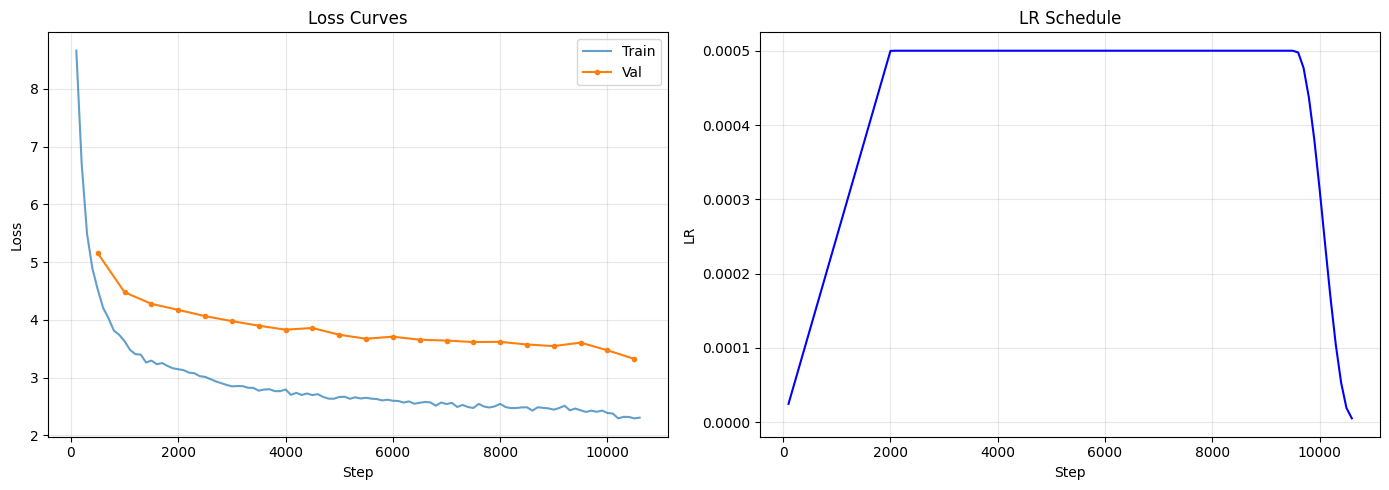

In [25]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot([d["step"] for d in train_log], [d["loss"] for d in train_log], label="Train", alpha=0.7)
ax1.plot([d["step"] for d in val_log], [d["val_loss"] for d in val_log], label="Val", marker="o", ms=3)
ax1.set_xlabel("Step"); ax1.set_ylabel("Loss"); ax1.set_title("Loss Curves"); ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot([d["step"] for d in train_log], [d["lr"] for d in train_log], color="blue")
ax2.set_xlabel("Step"); ax2.set_ylabel("LR"); ax2.set_title("LR Schedule"); ax2.grid(True, alpha=0.3)

plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=200); plt.show()

## 23. Load Best Checkpoint

In [26]:
print("Loading best checkpoint...")
best_step_loaded, _ = load_checkpoint(os.path.join(CHECKPOINT_DIR, "best.pt"), model)
print(f"Loaded best checkpoint from step {best_step_loaded}")

Loading best checkpoint...
Loaded best checkpoint from step 10500


## 24. Decoding Strategy Optimization

In [27]:
import bert_score

# --- Step 1: Prepare validation samples for decoding search ---
print("Preparing validation samples for decoding strategy search...")

# Load some raw documents for decoding evaluation
# We need (prompt, ground_truth_continuation) pairs
val_search_pairs = []
for source_name, fpath in train_file_paths.items():
    if len(val_search_pairs) >= DECODING_SEARCH_SAMPLES:
        break
    with open(fpath, "rb") as f:
        for rec in ijson.items(f, "item"):
            text = rec.get("text", "")
            words = text.split()
            if len(words) < 300:
                continue
            # Split: first 80% as prompt, last 20% as reference continuation
            split_idx = int(len(words) * 0.8)
            prompt = " ".join(words[:split_idx])
            reference = " ".join(words[split_idx:split_idx + TARGET_GENERATION_WORDS])
            val_search_pairs.append((prompt, reference))
            if len(val_search_pairs) >= DECODING_SEARCH_SAMPLES:
                break

print(f"Prepared {len(val_search_pairs)} validation pairs for decoding search")

# --- Step 2: Define decoding configurations to search ---
decoding_configs = [
    # Greedy
    {"name": "greedy", "strategy": "greedy", "temperature": 1.0, "top_p": 1.0, "top_k": 0, "repetition_penalty": 1.0},
    # Nucleus variants
    {"name": "nucleus_t03_p09", "strategy": "nucleus", "temperature": 0.3, "top_p": 0.9, "top_k": 50, "repetition_penalty": 1.1},
    {"name": "nucleus_t05_p09", "strategy": "nucleus", "temperature": 0.5, "top_p": 0.9, "top_k": 50, "repetition_penalty": 1.1},
    {"name": "nucleus_t07_p09", "strategy": "nucleus", "temperature": 0.7, "top_p": 0.9, "top_k": 50, "repetition_penalty": 1.1},
    {"name": "nucleus_t05_p095", "strategy": "nucleus", "temperature": 0.5, "top_p": 0.95, "top_k": 50, "repetition_penalty": 1.1},
    {"name": "nucleus_t03_p085", "strategy": "nucleus", "temperature": 0.3, "top_p": 0.85, "top_k": 50, "repetition_penalty": 1.1},
    # Contrastive variants
    {"name": "contrastive_k4_a06", "strategy": "contrastive", "temperature": 0.5, "contrastive_k": 4, "contrastive_alpha": 0.6, "repetition_penalty": 1.1},
    {"name": "contrastive_k6_a06", "strategy": "contrastive", "temperature": 0.5, "contrastive_k": 6, "contrastive_alpha": 0.6, "repetition_penalty": 1.1},
    # Low-temperature greedy-ish (for BERTScore — semantic fidelity matters more than diversity)
    {"name": "nucleus_t02_p085", "strategy": "nucleus", "temperature": 0.2, "top_p": 0.85, "top_k": 30, "repetition_penalty": 1.15},
]

# --- Step 3: Run search ---
model.eval()
best_config = None
best_bertscore = -1.0
search_results = []

for config in decoding_configs:
    print(f"\nTesting: {config['name']}...")
    predictions = []
    references = []
    
    with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
        for prompt, ref in tqdm(val_search_pairs, desc=config['name'], leave=False):
            # Tokenize prompt
            enc_ids = tokenizer.encode(prompt, add_special_tokens=False)
            enc_ids = enc_ids[-MAX_ENC_LEN:]  # Truncate to fit
            enc_input = torch.tensor([enc_ids], dtype=torch.long, device=device)
            enc_mask = torch.ones_like(enc_input)
            
            # Generate
            output_ids = model.generate(
                enc_input, enc_mask,
                max_new_tokens=MAX_GENERATION_TOKENS,
                strategy=config.get("strategy", "nucleus"),
                temperature=config.get("temperature", 0.7),
                top_p=config.get("top_p", 0.9),
                top_k=config.get("top_k", 50),
                repetition_penalty=config.get("repetition_penalty", 1.1),
                contrastive_k=config.get("contrastive_k", 4),
                contrastive_alpha=config.get("contrastive_alpha", 0.6),
                eos_token_id=EOS_TOKEN_ID,
                bos_token_id=BOS_TOKEN_ID,
                pad_token_id=PAD_TOKEN_ID,
            )
            
            # Decode (skip BOS token)
            gen_tokens = output_ids[0, 1:].tolist()
            gen_text = tokenizer.decode(gen_tokens, skip_special_tokens=True)
            gen_words = gen_text.split()[:TARGET_GENERATION_WORDS]
            predictions.append(" ".join(gen_words))
            references.append(ref)
    
    # Compute BERTScore
    _, _, f1 = bert_score.score(predictions, references, lang='en', batch_size=16, verbose=False,
                                device='cuda' if torch.cuda.is_available() else 'cpu')
    avg_bertscore = float(f1.mean().item())
    
    result = {"name": config["name"], "bertscore_f1": avg_bertscore, "config": config}
    search_results.append(result)
    print(f"  BERTScore F1: {avg_bertscore:.6f}")
    
    if avg_bertscore > best_bertscore:
        best_bertscore = avg_bertscore
        best_config = config

print(f"\n{'='*60}")
print(f"BEST DECODING CONFIG: {best_config['name']}")
print(f"BEST BERTScore F1: {best_bertscore:.6f}")
print(f"Config: {best_config}")
print(f"{'='*60}")

Preparing validation samples for decoding strategy search...


NameError: name 'train_file_paths' is not defined

## 25. Load Test Prompts

In [ ]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print(f"Number of test examples: {len(test_data)}")

## 26. Generate Predictions with Optimized Decoding

In [ ]:
model.eval()
predictions = {}
items = list(test_data.items())
print(f"Generating with best config: {best_config['name']}")

gen_start = time.time()

with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
    for idx, (example_id, record) in enumerate(tqdm(items, desc="Generating")):
        prompt = record["text"]
        
        enc_ids = tokenizer.encode(prompt, add_special_tokens=False)
        enc_ids = enc_ids[-MAX_ENC_LEN:]
        enc_input = torch.tensor([enc_ids], dtype=torch.long, device=device)
        enc_mask = torch.ones_like(enc_input)
        
        output_ids = model.generate(
            enc_input, enc_mask,
            max_new_tokens=MAX_GENERATION_TOKENS,
            strategy=best_config.get("strategy", "nucleus"),
            temperature=best_config.get("temperature", 0.7),
            top_p=best_config.get("top_p", 0.9),
            top_k=best_config.get("top_k", 50),
            repetition_penalty=best_config.get("repetition_penalty", 1.1),
            contrastive_k=best_config.get("contrastive_k", 4),
            contrastive_alpha=best_config.get("contrastive_alpha", 0.6),
            eos_token_id=EOS_TOKEN_ID,
            bos_token_id=BOS_TOKEN_ID,
            pad_token_id=PAD_TOKEN_ID,
        )
        
        gen_tokens = output_ids[0, 1:].tolist()
        gen_text = tokenizer.decode(gen_tokens, skip_special_tokens=True)
        gen_words = gen_text.split()[:TARGET_GENERATION_WORDS]
        predictions[str(example_id)] = {"text": " ".join(gen_words)}

gen_time = time.time() - gen_start
print(f"Generation complete in {gen_time:.1f}s ({gen_time/len(items):.2f}s/example)")

## 27. Save prediction.json

In [ ]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

test_ids = set(str(k) for k in test_data.keys())
pred_ids = set(predictions.keys())
assert test_ids == pred_ids, f"ID mismatch!"
print(f"prediction.json saved: {len(predictions)} predictions")

## 28. Create Submission ZIP

In [ ]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")
print(f"Submission ZIP: {SUBMISSION_ZIP} ({os.path.getsize(SUBMISSION_ZIP)/1024:.1f} KB)")

## 29. Sample Generations

In [ ]:
print("=" * 80)
print("SAMPLE GENERATIONS")
print("=" * 80)
for eid, rec in list(test_data.items())[:3]:
    prompt = rec["text"]
    pred = predictions[str(eid)]["text"]
    print(f"\n{'---'*27}")
    print(f"ID: {eid}")
    print(f"PROMPT (last 100 words): ...{' '.join(prompt.split()[-100:])}")
    print(f"\nGENERATED ({len(pred.split())} words): {pred}")

## 30. Save Model & Training Summary

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "config": {
        "vocab_size": VOCAB_SIZE, "d_model": D_MODEL,
        "enc_layers": ENC_LAYERS, "dec_layers": DEC_LAYERS,
        "n_heads": N_HEADS, "head_dim": HEAD_DIM, "d_ff": D_FF,
        "max_enc_len": MAX_ENC_LEN, "max_dec_len": MAX_DEC_LEN,
        "architecture": "encoder-decoder",
    },
    "best_decoding_config": best_config,
    "decoding_search_results": search_results,
}, os.path.join(MODEL_OUTPUT_DIR, "model.pt"))

tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print("=" * 60)
print("ENCODER-DECODER TRAINING SUMMARY")
print("=" * 60)
print(f"Architecture: Encoder-Decoder ({ENC_LAYERS}L enc + {DEC_LAYERS}L dec)")
print(f"Components: RoPE + RMSNorm + SwiGLU + 3-way tied embeddings")
print(f"Parameters: {unique_params/1e6:.1f}M")
print(f"Tokenizer: Custom BPE (vocab={VOCAB_SIZE})")
print(f"Training objective: Denoising ({DENOISE_PROB*100:.0f}%) + Continuation ({CONTINUATION_PROB*100:.0f}%)")
print(f"Best val loss: {best_val_loss:.4f} (step {best_step})")
print(f"Best decoding: {best_config['name']} (BERTScore F1={best_bertscore:.6f})")
print(f"Total training time: {total_time/3600:.2f}h")
print("=" * 60)